# 04. Calibración Probabilística, Aprendizaje Incremental (*Streaming*) y Benchmark Integral

**Módulo:** `05_Naive_Bayes`  
**Objetivo:** Analizar la patología de sobreconfianza probabilística en Naive Bayes y corregirla mediante `CalibratedClassifierCV` (Escalado de Platt y Regresión Isotónica) evaluando Curvas de Confiabilidad y el *Brier Score*; demostrar analíticamente la actualización incremental de estadísticas suficientes e implementar arquitecturas de aprendizaje fuera de núcleo (*Out-of-Core / Streaming*) con `partial_fit` y `HashingVectorizer` para flujos masivos de datos; y ejecutar un benchmark multidimensional (calidad predictiva, escalabilidad temporal $\mathcal{O}(N \cdot D)$ y latencia de inferencia) frente a Regresión Logística, KNN, Árboles CART y Random Forest.

---

## 1. La Patología de Probabilidades No Calibradas en Naive Bayes

### Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
En los cuadernos anteriores demostramos que Naive Bayes puede alcanzar una alta exactitud de clasificación (buen *ranking* relativo) incluso cuando las características están correlacionadas. Sin embargo, ¿qué sucede cuando el área de Riesgo Crediticio o *AdTech* no solo necesita saber si un cliente hará *default* o clic (`.predict(X)`), sino que requiere multiplicar la probabilidad exacta (`.predict_proba(X)`) por un monto monetario para calcular la **Pérdida Esperada** ($\text{EL} = \text{PD} \times \text{LGD} \times \text{EAD}$)?

Al inspeccionar las probabilidades devueltas por `.predict_proba(X)` en Naive Bayes, observamos una patología severa: **el histograma de probabilidades se concentra masivamente en los extremos `0.0001` y `0.9999`**. Si el modelo asigna una probabilidad de $0.999$ a un grupo de clientes cuya tasa real de *default* es del $65\%$, el banco sobreestimará las reservas de capital y rechazará operaciones rentables.

---

### Paso 2: Formalismo Matemático Riguroso (Demostración Algebraica de la Sobreconfianza)

Consideremos un problema de clasificación binaria $Y \in \{0, 1\}$. La razón de probabilidades posteriores (*Posterior Odds*) en espacio logarítmico (el **Logit** estimado por Naive Bayes) es:

$$\ln \frac{\hat{P}_{\text{NB}}(Y=1 \mid \mathbf{x})}{\hat{P}_{\text{NB}}(Y=0 \mid \mathbf{x})} = \ln \frac{P(Y=1)}{P(Y=0)} + \sum_{j=1}^{D} \ln \frac{P(x_j \mid Y=1)}{P(x_j \mid Y=0)}$$

Supongamos el caso canónico donde una característica informativa $X_1$ está duplicada $m$ veces en el conjunto de datos (o existen $m$ características altamente colineales que aportan exactamente la misma señal de evidencia $\Delta = \ln \frac{P(x_1 \mid Y=1)}{P(x_1 \mid Y=0)} > 0$) y Priors balanceados ($\ln \frac{P(Y=1)}{P(Y=0)} = 0$):

1. **Logit Verdadero (Realidad Condicional):** Dado que las $m$ variables contienen exactamente la misma información redundante ($P(x_1, \dots, x_m \mid Y) = P(x_1 \mid Y)$), el *log-odds* verdadero es simplemente:
   $$z_{\text{real}} = \Delta \implies P_{\text{real}}(Y=1 \mid \mathbf{x}) = \sigma(\Delta) = \frac{1}{1 + e^{-\Delta}}$$
2. **Logit de Naive Bayes (Conteo Múltiple de Evidencia):** Al asumir independencia condicional, Naive Bayes multiplica $m$ veces el mismo factor (suma $m$ veces la misma evidencia en espacio logarítmico):
   $$z_{\text{NB}} = \sum_{j=1}^{m} \Delta = m \cdot \Delta \implies \hat{P}_{\text{NB}}(Y=1 \mid \mathbf{x}) = \sigma(m \cdot \Delta) = \frac{1}{1 + e^{-m \Delta}}$$
3. **Colapso hacia los Extremos:** Cuando $m$ crece, el factor multiplicativo $m$ empuja el argumento de la función logística hacia $+\infty$ (si $\Delta > 0$) o hacia $-\infty$ (si $\Delta < 0$), provocando que $\hat{P}_{\text{NB}}(Y=1 \mid \mathbf{x}) \to 1$ o $0$.

#### Definición Formal de Calibración Perfecta
Un clasificador probabilístico está **perfectamente calibrado** si, para cualquier nivel de confianza predicho $p \in [0, 1]$, la proporción empírica real de muestras positivas entre todas las instancias que recibieron dicho puntaje coincide exactamente con $p$:

$$P\left(Y = 1 \; \middle| \; \hat{P}(Y=1 \mid \mathbf{X}) = p\right) = p \quad \forall p \in [0, 1]$$

---

### Paso 3: Traducción "En Palabras Claras" (El Puente Conceptual)

| Concepto / Fenómeno | ¿Qué ocurre internamente? | Impacto en Toma de Decisiones de Negocio |
| :--- | :--- | :--- |
| **Conteo múltiple por colinealidad ($m \cdot \Delta$)** | Si un correo tiene 5 palabras sinónimas correlacionadas, Naive Bayes actúa como si hubiera escuchado a 5 testigos independientes en lugar de al mismo testigo repitiendo lo mismo 5 veces. | El ordenamiento (*ranking* / ROC-AUC) se conserva, pero la probabilidad numérica se deforma hacia `0.0001` o `0.9999`. |
| **Curva de Confiabilidad (*Reliability Diagram*)** | Agrupa las predicciones en *bins* (ej. $[0.7, 0.8]$) y grafica la probabilidad media predicha (eje X) contra la fracción real de positivos (eje Y). | Un modelo bien calibrado sigue la **diagonal de $45^\circ$**. Naive Bayes crudo dibuja una curva distorsionada lejos de la diagonal. |
| **Casos donde la calibración es obligatoria** | Riesgo crediticio ($\text{EL} = \text{PD} \times \text{LGD} \times \text{EAD}$), subastas publicitarias (*Real-Time Bidding*: $\text{Bid} = P(\text{Click}) \times \text{Valor}$) y diagnóstico clínico. | Nunca uses `.predict_proba()` de Naive Bayes crudo en fórmulas financieras sin antes pasar por un calibrador post-hoc. |

In [1]:
# Configuración del entorno y librerías estándar
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    brier_score_loss, log_loss
)

# Estándar visual del repositorio
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

print("Entorno configurado correctamente.")

Entorno configurado correctamente.


---

## 2. Evaluación y Corrección de la Calibración: Brier Score, Escalado de Platt y Regresión Isotónica

### Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
Sabemos que Naive Bayes es un excelente clasificador por *ranking*, pero un mal estimador de probabilidades crudas. ¿Cómo podemos conservar la velocidad de entrenamiento de Naive Bayes y, al mismo tiempo, **corregir sus probabilidades extremas para que reflejen frecuencias reales**?  
La solución consiste en aprender una función traductora liviana encima de la salida de Naive Bayes (usando datos de validación para no sobreajustar) que "descomprima" las probabilidades pegadas a $0$ y $1$ y las devuelva a la diagonal de calibración.

---

### Paso 2: Formalismo Matemático Riguroso

#### A. Métrica Cuantitativa: El Puntaje de Brier (*Brier Score*)
El **Brier Score** mide el Error Cuadrático Medio (*MSE*) entre las probabilidades predichas $\hat{p}_i = \hat{P}(Y=1 \mid \mathbf{x}_i)$ y las etiquetas binarias reales $y_i \in \{0, 1\}$:

$$\text{BS} = \frac{1}{N} \sum_{i=1}^{N} \left(y_i - \hat{p}_i\right)^2$$

* Es una **regla de puntuación estrictamente propia** (*strictly proper scoring rule*): alcanza su mínimo único si y solo si el modelo predice la verdadera probabilidad condicional del proceso generador de datos.
* **Rango:** $[0, 1]$, donde **`0.0` es perfecto** y un modelo no informativo que predice siempre $0.5$ en clases balanceadas obtiene $\text{BS} = 0.25$.

#### B. Métodos de Recalibración Post-Hoc en `CalibratedClassifierCV`
Dado el puntaje crudo no calibrado $s_i = \hat{P}_{\text{NB}}(Y=1 \mid \mathbf{x}_i)$ devuelto por Naive Bayes sobre pliegues fuera de muestra (*Out-of-Fold* vía validación cruzada interna para evitar *data leakage*), ajustamos un mapeo monótono $g: [0, 1] \to [0, 1]$:

1. **Escalado de Platt (`method='sigmoid'` — Paramétrico):**  
   Ajusta una regresión logística univariada de dos parámetros escalares $(A, B \in \mathbb{R})$ minimizando la entropía cruzada sobre los puntajes $s_i$:
   $$\hat{P}_{\text{cal}}(Y = 1 \mid s_i) = \frac{1}{1 + \exp(A \cdot s_i + B)}$$
2. **Regresión Isotónica (`method='isotonic'` — No Paramétrico):**  
   Ajusta una función escalonada constante a trozos monótonamente no decreciente $m(\cdot)$ mediante el algoritmo *Pool Adjacent Violators Algorithm* (PAVA) resolviendo el programa cuadrático con restricciones de orden:
   $$\underset{m_1 \le m_2 \le \dots \le m_N}{\min} \sum_{i=1}^{N} \left(y_i - m(s_i)\right)^2 \quad \text{sujeto a } m(s_i) \le m(s_j) \; \forall s_i < s_j$$

---

### Paso 3: Traducción "En Palabras Claras" (Guía de Elección: Sigmoid vs. Isotonic)

| Método en `CalibratedClassifierCV` | Naturaleza Matemática | Capacidad y Flexibilidad | Tamaño de Muestra Recomendado ($N$) | Riesgo Principal |
| :--- | :--- | :--- | :--- | :--- |
| **`method='sigmoid'` (Platt Scaling)** | Paramétrica (2 grados de libertad: pendiente $A$ e intercepto $B$). | Corrige distorsiones simétricas con forma de "S" sigmoidal. | **Datasets pequeños o medianos ($N < 1,000$ muestras).** | Si la distorsión de calibración es asimétrica o compleja, no logra alinearla por completo. |
| **`method='isotonic'` (Regresión Isotónica)** | No paramétrica (función escalonada libre monótona). | Corrige **cualquier distorsión monótona arbitraria** con alta precisión. | **Datasets medianos o grandes ($N > 1,000$ muestras).** | Con pocos datos ($N$ pequeño) sobreajusta los escalones produciendo probabilidades ruidosas. |

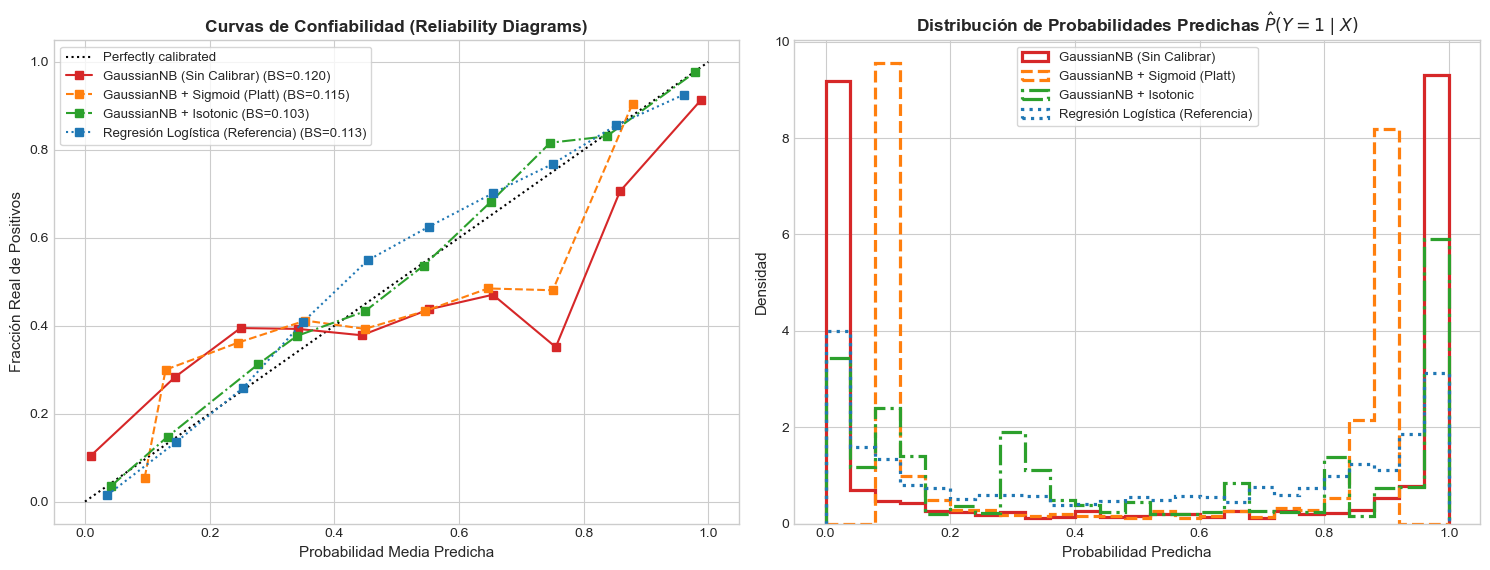

=== AUDITORÍA CUANTITATIVA DE CALIBRACIÓN EN TEST ===


,Brier Score (menor es mejor),Log-Loss (menor es mejor),Accuracy (mayor es mejor),ROC-AUC (mayor es mejor)
Modelo,,,,
GaussianNB (Sin Calibrar),0.1200,0.4860,84.78%,0.9333
GaussianNB + Sigmoid (Platt),0.1149,0.3797,84.89%,0.9334
GaussianNB + Isotonic,0.1031,0.3407,85.44%,0.9335
Regresión Logística (Referencia),0.1133,0.3619,84.11%,0.9176


In [2]:
# Paso 4: Experimento de Calibración: GaussianNB Crudo vs Platt Scaling (Sigmoid) vs Regresión Isotónica
np.random.seed(42)

# Generamos un dataset con alta redundancia (n_redundant=12) que induce fuerte colinealidad
X_cal, y_cal = make_classification(
    n_samples=6000, n_features=20, n_informative=6, n_redundant=12,
    n_clusters_per_class=2, weights=[0.5, 0.5], random_state=42
)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cal, y_cal, test_size=0.30, stratify=y_cal, random_state=42
)

# Modelos a comparar
gnb_uncal = GaussianNB().fit(X_train_c, y_train_c)
gnb_sigmoid = CalibratedClassifierCV(GaussianNB(), method='sigmoid', cv=5).fit(X_train_c, y_train_c)
gnb_isotonic = CalibratedClassifierCV(GaussianNB(), method='isotonic', cv=5).fit(X_train_c, y_train_c)
lr_ref = LogisticRegression(max_iter=1000).fit(X_train_c, y_train_c)

modelos_cal = [
    ("GaussianNB (Sin Calibrar)", gnb_uncal, '#d62728', '-'),
    ("GaussianNB + Sigmoid (Platt)", gnb_sigmoid, '#ff7f0e', '--'),
    ("GaussianNB + Isotonic", gnb_isotonic, '#2ca02c', '-.'),
    ("Regresión Logística (Referencia)", lr_ref, '#1f77b4', ':')
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

tabla_metricas_cal = []

for nombre, clf, color, ls in modelos_cal:
    y_prob = clf.predict_proba(X_test_c)[:, 1]
    y_pred = clf.predict(X_test_c)
    
    brier = brier_score_loss(y_test_c, y_prob)
    lloss = log_loss(y_test_c, y_prob)
    acc = accuracy_score(y_test_c, y_pred)
    auc = roc_auc_score(y_test_c, y_prob)
    
    tabla_metricas_cal.append({
        'Modelo': nombre,
        'Brier Score (menor es mejor)': brier,
        'Log-Loss (menor es mejor)': lloss,
        'Accuracy (mayor es mejor)': acc,
        'ROC-AUC (mayor es mejor)': auc
    })
    
    # Curva de Confiabilidad (Reliability Diagram)
    CalibrationDisplay.from_estimator(
        clf, X_test_c, y_test_c, n_bins=10, name=f"{nombre} (BS={brier:.3f})",
        ax=axes[0], color=color, linestyle=ls
    )
    
    # Histograma de probabilidades predichas
    axes[1].hist(y_prob, bins=25, range=(0, 1), histtype='step', lw=2.3,
                 label=nombre, color=color, linestyle=ls, density=True)

axes[0].set_title("Curvas de Confiabilidad (Reliability Diagrams)", fontsize=12.5, fontweight='bold')
axes[0].set_xlabel("Probabilidad Media Predicha", fontsize=11)
axes[0].set_ylabel("Fracción Real de Positivos", fontsize=11)
axes[0].legend(loc='upper left', frameon=True, facecolor='white', fontsize=9.5)

axes[1].set_title("Distribución de Probabilidades Predichas $\hat{P}(Y=1 \mid X)$", fontsize=12.5, fontweight='bold')
axes[1].set_xlabel("Probabilidad Predicha", fontsize=11)
axes[1].set_ylabel("Densidad", fontsize=11)
axes[1].legend(loc='upper center', frameon=True, facecolor='white', fontsize=9.5)

plt.tight_layout()
plt.show()

df_cal = pd.DataFrame(tabla_metricas_cal).set_index('Modelo')
print("=== AUDITORÍA CUANTITATIVA DE CALIBRACIÓN EN TEST ===")
display(df_cal.style.format({
    'Brier Score (menor es mejor)': '{:.4f}',
    'Log-Loss (menor es mejor)': '{:.4f}',
    'Accuracy (mayor es mejor)': '{:.2%}',
    'ROC-AUC (mayor es mejor)': '{:.4f}'
}))

---

## 3. Aprendizaje Fuera de Núcleo (*Out-of-Core / Streaming*) con `partial_fit` y `HashingVectorizer`

### Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
¿Qué sucede cuando necesitamos entrenar un clasificador sobre un archivo histórico de *logs* de seguridad de **100 GB** o sobre un flujo ininterrumpido de eventos en Apache Kafka, pero nuestro contenedor en la nube solo cuenta con **4 GB de memoria RAM**?
* Algoritmos como `RandomForestClassifier`, `SVC` o `KNeighborsClassifier` exigen cargar la matriz de datos completa en memoria RAM o reentrenar desde cero con todo el histórico cada vez que llegan datos nuevos.
* **¿Por qué Naive Bayes es uno de los poquísimos modelos clásicos que soporta *streaming* puro mediante `.partial_fit()` con memoria constante $\mathcal{O}(1)$?** Porque para estimar sus parámetros no necesita recordar las filas individuales del pasado: le basta con llevar **contadores acumulados** (estadísticas suficientes) que se actualizan algebraicamente lote a lote.

---

### Paso 2: Formalismo Matemático Riguroso (Actualización Incremental Exacta)

Demostremos analíticamente cómo Naive Bayes actualiza sus parámetros exactos al recibir un nuevo lote (*mini-batch*) de datos sin acceder a los datos históricos previos:

#### A. Actualización Aditiva en Modelos Discretos (`MultinomialNB`, `BernoulliNB`, `ComplementNB`)
Las estadísticas suficientes son únicamente los conteos de clase $N_k$ y los conteos de características por clase $N_{kj}$. Si en el instante $t$ tenemos los acumuladores históricos $N_{kj}^{(t)}$ y llega un nuevo lote $B$ con conteos locales $N_{kj}^{(B)} = \sum_{i \in B_k} x_{ij}$, el nuevo estado global en $t+1$ es exactamente la suma directa:

$$N_k^{(t+1)} = N_k^{(t)} + N_k^{(B)}, \qquad N_{kj}^{(t+1)} = N_{kj}^{(t)} + N_{kj}^{(B)}$$

#### B. Actualización por Lotes en `GaussianNB` (Fórmulas de Chan, Golub & LeVeque / Welford)
Supongamos que para una clase y característica fija ya hemos procesado un bloque histórico de $N_1$ muestras con media $\mu_1$ y varianza $\sigma_1^2$, y recibimos un nuevo lote de $N_2$ muestras con media $\mu_2$ y varianza $\sigma_2^2$.

1. **Actualización exacta de la media combinada ($\mu_{\text{nuevo}}$):**
   Dado que $\sum_{i=1}^{N_1} x_i = N_1 \mu_1$ y $\sum_{i=N_1+1}^{N_1+N_2} x_i = N_2 \mu_2$, el nuevo centro de masa es el promedio ponderado:
   $$\boxed{\mu_{\text{nuevo}} = \frac{N_1 \mu_1 + N_2 \mu_2}{N_1 + N_2}}$$

2. **Actualización exacta de la varianza combinada ($\sigma_{\text{nuevo}}^2$):**
   Descomponiendo la suma total de cuadrados respecto al nuevo centro $\mu_{\text{nuevo}}$, la nueva varianza se actualiza en tiempo constante $\mathcal{O}(1)$ mediante:
   $$\boxed{\sigma_{\text{nuevo}}^2 = \frac{N_1 \sigma_1^2 + N_2 \sigma_2^2}{N_1 + N_2} + \frac{N_1 N_2}{(N_1 + N_2)^2} (\mu_1 - \mu_2)^2}$$

#### C. Vectorización de Texto Sin Estado (*Stateless*): `HashingVectorizer`
En un flujo de texto continuo, `CountVectorizer` y `TfidfVectorizer` rompen el paradigma de *streaming* porque requieren almacenar un diccionario de vocabulario en RAM que crece indefinidamente con nuevas palabras. **`HashingVectorizer`** aplica una función *hash* determinista (MurmurHash3) directamente sobre cada token $w$ para proyectarlo a un índice de columna fijo:

$$j = h(w) \pmod{D}, \quad \text{con } D = 2^b \text{ (ej. } 2^{12} = 4,096\text{)}$$

sin guardar ningún diccionario en memoria.

---

### Paso 3: Traducción "En Palabras Claras" (Reglas de Ingeniería para Pipelines Streaming)

| Componente en Streaming | Configuración Crítica en Scikit-Learn | ¿Por qué es indispensable? |
| :--- | :--- | :--- |
| **Actualización Incremental** | `clf.partial_fit(X_batch, y_batch, classes=np.array([0, 1]))` | El argumento `classes` es **obligatorio en la primera llamada** por si el primer *mini-batch* no contiene ejemplos de todas las clases posibles. |
| **`HashingVectorizer` para `MultinomialNB`** | `HashingVectorizer(n_features=2**12, alternate_sign=False, norm=None)` | Por defecto `alternate_sign=True` introduce signos negativos para cancelar colisiones hash, pero `MultinomialNB` exige conteos estrictamente no negativos ($x_j \ge 0$). Por ello, **`alternate_sign=False` es obligatorio**. |

=== 1. VERIFICACIÓN ALGEBRAICA DE ACTUALIZACIÓN ONLINE (CHAN / WELFORD) ===
Media Combinada    -> Fórmula Analítica: 3.23408136 | partial_fit: 3.23408136 | Batch Completo: 3.23408136
Varianza Combinada -> Fórmula Analítica: 4.66567422 | partial_fit: 4.66567422 | Batch Completo: 4.66567422



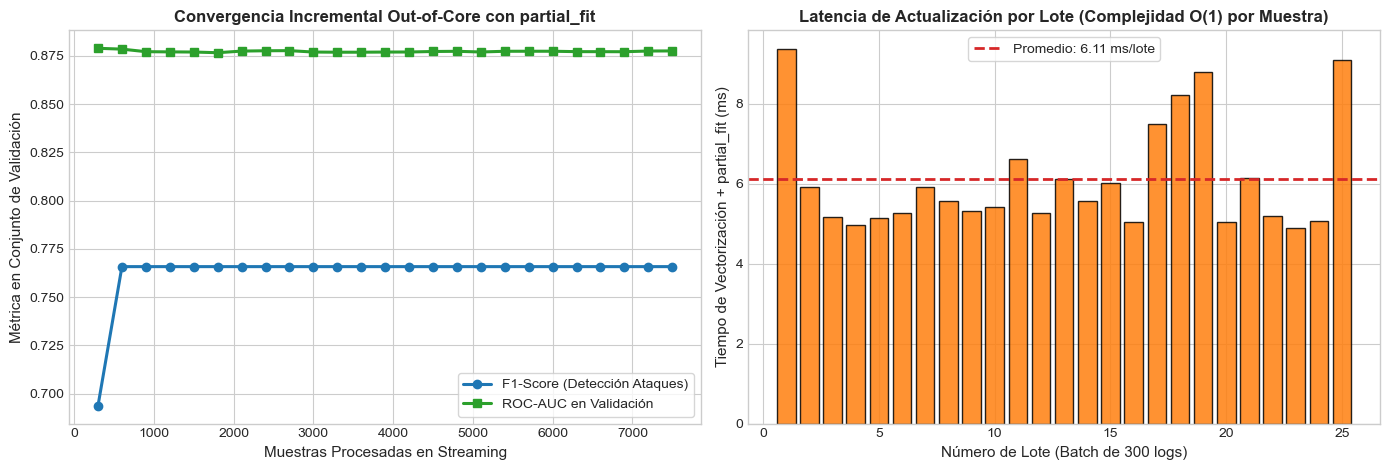

In [3]:
# Paso 4: Verificación Algebraica de Actualización Incremental y Simulación de Pipeline Streaming (HashingVectorizer + partial_fit)
np.random.seed(42)

# 1. Verificación empírica de que las fórmulas incrementales de media y varianza coinciden con GaussianNB.partial_fit
lote_1 = np.random.normal(loc=2.0, scale=1.5, size=(300, 1))
lote_2 = np.random.normal(loc=4.0, scale=2.2, size=(500, 1))
datos_completos = np.vstack([lote_1, lote_2])
y_d1, y_d2, y_full_d = np.zeros(300), np.zeros(500), np.zeros(800)

N1, mu1, var1 = len(lote_1), lote_1.mean(), lote_1.var(ddof=0)
N2, mu2, var2 = len(lote_2), lote_2.mean(), lote_2.var(ddof=0)

mu_formula = (N1 * mu1 + N2 * mu2) / (N1 + N2)
var_formula = (N1 * var1 + N2 * var2) / (N1 + N2) + (N1 * N2 / (N1 + N2)**2) * (mu1 - mu2)**2

gnb_inc = GaussianNB(var_smoothing=0.0)
gnb_inc.partial_fit(lote_1, y_d1, classes=np.array([0]))
gnb_inc.partial_fit(lote_2, y_d2)

print("=== 1. VERIFICACIÓN ALGEBRAICA DE ACTUALIZACIÓN ONLINE (CHAN / WELFORD) ===")
print(f"Media Combinada    -> Fórmula Analítica: {mu_formula:.8f} | partial_fit: {gnb_inc.theta_[0,0]:.8f} | Batch Completo: {datos_completos.mean():.8f}")
print(f"Varianza Combinada -> Fórmula Analítica: {var_formula:.8f} | partial_fit: {gnb_inc.var_[0,0]:.8f} | Batch Completo: {datos_completos.var(ddof=0):.8f}\n")

# 2. Simulación de Arquitectura Streaming Out-of-Core en NLP
vocab_stream = {
    0: ['normal', 'login', 'consulta', 'saldo', 'transferencia', 'recibo', 'pago', 'autorizado', 'ok', 'cliente'],
    1: ['alerta', 'exploit', 'sql_injection', 'payload', 'root', 'fuerza_bruta', 'timeout', 'bloqueo', 'malware', 'ddos']
}
vocab_ruido_stream = ['ip', 'puerto', 'servidor', 'request', 'response', 'http', 'sesion', 'token', 'timestamp']

def stream_logs_generator(n_batches: int, batch_size: int = 400, seed: int = 42):
    """Generador perezoso (lazy generator) que simula lectura por lotes desde disco o Kafka sin usar RAM."""
    rng = np.random.default_rng(seed)
    for b in range(n_batches):
        textos_batch, y_batch = [], []
        for _ in range(batch_size):
            clase = rng.choice([0, 1], p=[0.80, 0.20]) # 20% eventos de ataque
            n_palabras = rng.integers(8, 18)
            clase_efectiva = clase if rng.random() > 0.12 else (1 - clase)
            t_senal = rng.choice(vocab_stream[clase_efectiva], size=int(n_palabras*0.6), replace=True)
            t_ruido = rng.choice(vocab_ruido_stream, size=n_palabras - len(t_senal), replace=True)
            log_line = " ".join(np.concatenate([t_senal, t_ruido]))
            textos_batch.append(log_line)
            y_batch.append(clase)
        yield b + 1, textos_batch, np.array(y_batch)

# Vectorizador sin estado en memoria (Stateless) con 2^12 = 4096 columnas y no negatividad para MultinomialNB
hasher = HashingVectorizer(n_features=2**12, alternate_sign=False, norm=None)

# Reservamos un conjunto de validación fijo para medir la evolución del aprendizaje
_, textos_val_stream, y_val_stream = next(stream_logs_generator(1, batch_size=1200, seed=999))
X_val_stream = hasher.transform(textos_val_stream)

clf_streaming = MultinomialNB(alpha=0.5)
clases_totales = np.array([0, 1])

historial_batches = []
muestras_acumuladas = 0

for batch_id, textos_b, y_b in stream_logs_generator(n_batches=25, batch_size=300, seed=42):
    t0 = time.perf_counter()
    X_b = hasher.transform(textos_b)
    clf_streaming.partial_fit(X_b, y_b, classes=clases_totales)
    t_batch_ms = (time.perf_counter() - t0) * 1000
    
    muestras_acumuladas += len(y_b)
    y_pred_val = clf_streaming.predict(X_val_stream)
    y_prob_val = clf_streaming.predict_proba(X_val_stream)[:, 1]
    
    historial_batches.append({
        'Batch': batch_id,
        'Muestras_Acumuladas': muestras_acumuladas,
        'F1_Score_Ataques': f1_score(y_val_stream, y_pred_val),
        'ROC_AUC': roc_auc_score(y_val_stream, y_prob_val),
        'Tiempo_Batch_ms': t_batch_ms
    })

df_stream = pd.DataFrame(historial_batches)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].plot(df_stream['Muestras_Acumuladas'], df_stream['F1_Score_Ataques'], marker='o', color='#1f77b4', lw=2.2, label='F1-Score (Detección Ataques)')
axes[0].plot(df_stream['Muestras_Acumuladas'], df_stream['ROC_AUC'], marker='s', color='#2ca02c', lw=2.2, label='ROC-AUC en Validación')
axes[0].set_title('Convergencia Incremental Out-of-Core con partial_fit', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Muestras Procesadas en Streaming', fontsize=11)
axes[0].set_ylabel('Métrica en Conjunto de Validación', fontsize=11)
axes[0].legend(frameon=True, facecolor='white')

axes[1].bar(df_stream['Batch'], df_stream['Tiempo_Batch_ms'], color='#ff7f0e', alpha=0.85, edgecolor='k')
axes[1].axhline(df_stream['Tiempo_Batch_ms'].mean(), color='#d62728', linestyle='--', lw=2, label=f"Promedio: {df_stream['Tiempo_Batch_ms'].mean():.2f} ms/lote")
axes[1].set_title('Latencia de Actualización por Lote (Complejidad O(1) por Muestra)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Número de Lote (Batch de 300 logs)', fontsize=11)
axes[1].set_ylabel('Tiempo de Vectorización + partial_fit (ms)', fontsize=11)
axes[1].legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

---

## 4. Benchmark Integral: Calidad Predictiva, Escalabilidad Temporal y Latencia de Inferencia

### Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
En el diseño de sistemas de Machine Learning en producción, ningún algoritmo es superior en todas las dimensiones (Teorema *No Free Lunch*). Un arquitecto de ML debe justificar ante el negocio el *trade-off* entre **exactitud predictiva**, **calibración de probabilidades**, **costo de entrenamiento** y **latencia de inferencia en vivo** (ej. un motor antifraude que debe responder en menos de 50 microsegundos por transacción).

---

### Paso 2: Formalismo de Complejidad Computacional Asintótica

Sea $N$ el número de muestras de entrenamiento, $D$ la dimensionalidad del espacio de características, $C$ el número de clases, $T$ el número de árboles en un ensamble y $n_{\text{iter}}$ el número de iteraciones de un optimizador numérico:
* **Naive Bayes (`GaussianNB` / `MultinomialNB`):**
  * Entrenamiento: $\mathcal{O}(N \cdot D)$ (una única pasada de conteo o acumulación de momentos).
  * Inferencia por muestra: $\mathcal{O}(C \cdot D)$.
* **Regresión Logística (`LogisticRegression`):**
  * Entrenamiento: $\mathcal{O}(N \cdot D \cdot n_{\text{iter}})$.
  * Inferencia por muestra: $\mathcal{O}(C \cdot D)$.
* **K-Vecinos Más Cercanos (`KNeighborsClassifier`):**
  * Entrenamiento: $\mathcal{O}(1)$ (fuerza bruta) o $\mathcal{O}(N \cdot D \log N)$ (indexación espacial).
  * Inferencia por muestra: $\mathcal{O}(N \cdot D)$ (crece linealmente con el tamaño del dataset histórico).
* **Árboles CART y Random Forest:**
  * Entrenamiento: $\mathcal{O}(T \cdot N \cdot D \log N)$.
  * Inferencia por muestra: $\mathcal{O}(T \cdot \text{profundidad})$.

---

### Paso 3: Traducción "En Palabras Claras" (Diseño del Experimento Benchmark)

Enfrentaremos seis configuraciones sobre un mismo problema supervisado ($N = 15,000, D = 25$) y posteriormente escalaremos el tamaño muestral desde $N = 1,000$ hasta $N = 40,000$ para verificar empíricamente las curvas de complejidad temporal y construir la **Frontera de Pareto (Latencia de Inferencia vs. ROC-AUC)**.

In [4]:
# Paso 4 (Parte A): Benchmark de Calidad Predictiva, Tiempo de Entrenamiento y Latencia de Inferencia (N = 15,000, D = 25)
np.random.seed(42)

X_bench, y_bench = make_classification(
    n_samples=15000, n_features=25, n_informative=15, n_redundant=5,
    n_classes=2, class_sep=1.15, flip_y=0.03, random_state=42
)

X_tr_b, X_te_b, y_tr_b, y_te_b = train_test_split(
    X_bench, y_bench, test_size=0.25, stratify=y_bench, random_state=42
)

# Estandarizamos para que KNN y Regresión Logística compitan en igualdad de condiciones
scaler_b = StandardScaler()
X_tr_b = scaler_b.fit_transform(X_tr_b)
X_te_b = scaler_b.transform(X_te_b)

catalogo_modelos = {
    'GaussianNB (Crudo)': GaussianNB(),
    'GaussianNB (Calibrado Platt)': CalibratedClassifierCV(GaussianNB(), method='sigmoid', cv=3),
    'Regresión Logística': LogisticRegression(max_iter=500, random_state=42),
    'Árbol CART (max_depth=10)': DecisionTreeClassifier(max_depth=10, random_state=42),
    'KNN (k=15)': KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    'Random Forest (100 árboles)': RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42)
}

resultados_benchmark = []
n_test_samples = X_te_b.shape[0]

for nombre, modelo in catalogo_modelos.items():
    # Medición de tiempo de entrenamiento
    t0_fit = time.perf_counter()
    modelo.fit(X_tr_b, y_tr_b)
    t_fit_ms = (time.perf_counter() - t0_fit) * 1000
    
    # Medición de latencia de inferencia probabilística
    t0_pred = time.perf_counter()
    y_prob = modelo.predict_proba(X_te_b)[:, 1]
    t_pred_total_s = time.perf_counter() - t0_pred
    latencia_us_por_muestra = (t_pred_total_s / n_test_samples) * 1e6
    
    y_pred = (y_prob >= 0.5).astype(int)
    
    resultados_benchmark.append({
        'Familia / Modelo': nombre,
        'Accuracy': accuracy_score(y_te_b, y_pred),
        'F1-Weighted': f1_score(y_te_b, y_pred, average='weighted'),
        'ROC-AUC': roc_auc_score(y_te_b, y_prob),
        'Brier Score': brier_score_loss(y_te_b, y_prob),
        'Tiempo Train (ms)': t_fit_ms,
        'Latencia Inferencia (µs/muestra)': latencia_us_por_muestra
    })

df_bench = pd.DataFrame(resultados_benchmark).set_index('Familia / Modelo')
print("=== TABLA MAESTRA DE BENCHMARK (N_train = 11,250 | N_test = 3,750 | D = 25) ===")
display(df_bench.style.format({
    'Accuracy': '{:.2%}',
    'F1-Weighted': '{:.4f}',
    'ROC-AUC': '{:.4f}',
    'Brier Score': '{:.4f}',
    'Tiempo Train (ms)': '{:.2f} ms',
    'Latencia Inferencia (µs/muestra)': '{:.2f} µs'
}))

=== TABLA MAESTRA DE BENCHMARK (N_train = 11,250 | N_test = 3,750 | D = 25) ===


,Accuracy,F1-Weighted,ROC-AUC,Brier Score,Tiempo Train (ms),Latencia Inferencia (µs/muestra)
Familia / Modelo,,,,,,
GaussianNB (Crudo),82.29%,0.8229,0.9009,0.1284,11.97 ms,0.97 µs
GaussianNB (Calibrado Platt),82.29%,0.8229,0.9009,0.1281,58.08 ms,3.47 µs
Regresión Logística,85.84%,0.8584,0.9316,0.1032,21.86 ms,0.15 µs
Árbol CART (max_depth=10),86.77%,0.8677,0.8703,0.1192,689.13 ms,0.21 µs
KNN (k=15),95.04%,0.9504,0.9807,0.0459,1.67 ms,709.75 µs
Random Forest (100 árboles),93.33%,0.9333,0.9753,0.0659,1899.58 ms,13.75 µs


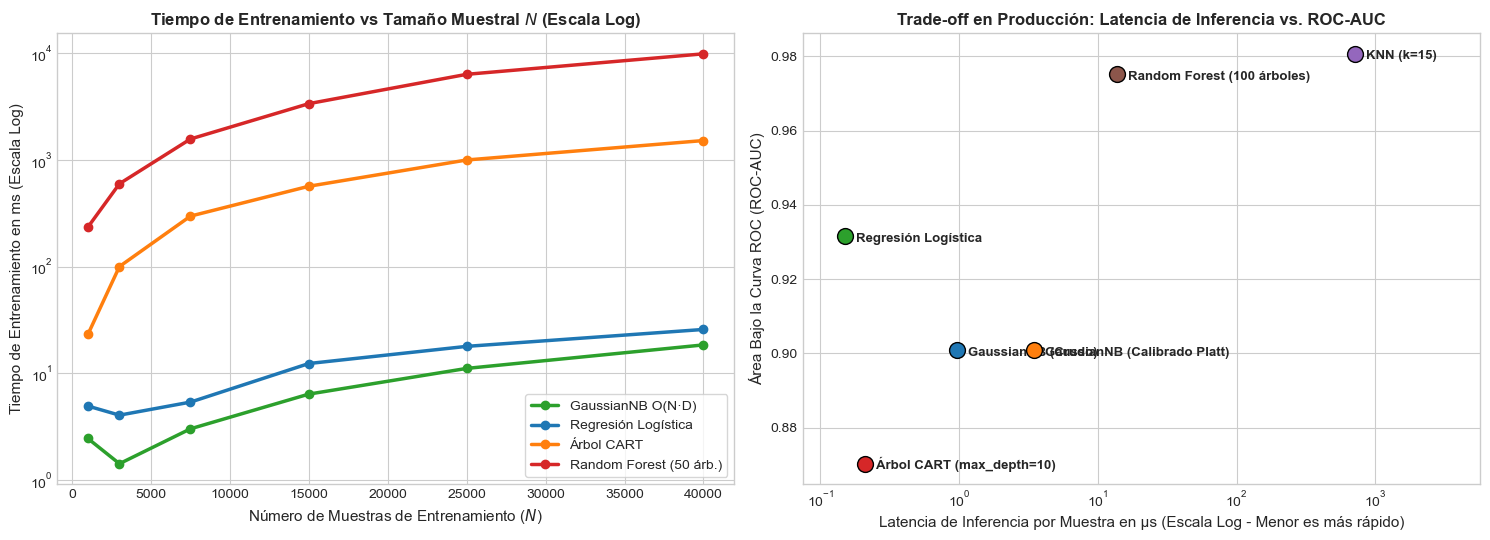

In [6]:
# Paso 4 (Parte B): Curvas de Escalabilidad Asintótica en Entrenamiento (Variando N desde 1,000 hasta 40,000)
tamanos_N = [1000, 3000, 7500, 15000, 25000, 40000]
modelos_escalabilidad = {
    'GaussianNB O(N·D)': GaussianNB(),
    'Regresión Logística': LogisticRegression(max_iter=300),
    'Árbol CART': DecisionTreeClassifier(max_depth=10),
    'Random Forest (50 árb.)': RandomForestClassifier(n_estimators=50, max_depth=10, n_jobs=1)
}

tiempos_por_N = {k: [] for k in modelos_escalabilidad}

X_large, y_large = make_classification(n_samples=max(tamanos_N), n_features=25, random_state=42)

for N_sub in tamanos_N:
    X_sub, y_sub = X_large[:N_sub], y_large[:N_sub]
    for nombre_m, clf_m in modelos_escalabilidad.items():
        t_ini = time.perf_counter()
        clf_m.fit(X_sub, y_sub)
        tiempos_por_N[nombre_m].append((time.perf_counter() - t_ini) * 1000)

# Visualización Comparativa: Escalabilidad vs Trade-off Latencia/ROC-AUC
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
colores_esc = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']

# Panel 1: Escalabilidad con N
for (nombre_m, lista_t), col in zip(tiempos_por_N.items(), colores_esc):
    axes[0].plot(tamanos_N, lista_t, marker='o', lw=2.5, label=nombre_m, color=col)

axes[0].set_yscale('log')
axes[0].set_title('Tiempo de Entrenamiento vs Tamaño Muestral $N$ (Escala Log)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Número de Muestras de Entrenamiento ($N$)', fontsize=11)
axes[0].set_ylabel('Tiempo de Entrenamiento en ms (Escala Log)', fontsize=11)
axes[0].legend(frameon=True, facecolor='white', fontsize=10)

# Panel 2: Frontera de Pareto (Latencia de Inferencia vs ROC-AUC)
for idx, row in df_bench.iterrows():
    axes[1].scatter(row['Latencia Inferencia (µs/muestra)'], row['ROC-AUC'], s=130, edgecolor='k', zorder=5)
    axes[1].annotate(
        idx, (row['Latencia Inferencia (µs/muestra)'], row['ROC-AUC']),
        xytext=(8, -4), textcoords='offset points', fontsize=9.5, fontweight='bold'
    )

axes[1].set_xscale('log')
axes[1].set_title('Trade-off en Producción: Latencia de Inferencia vs. ROC-AUC', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Latencia de Inferencia por Muestra en µs (Escala Log - Menor es más rápido)', fontsize=11)
axes[1].set_ylabel('Área Bajo la Curva ROC (ROC-AUC)', fontsize=11)
axes[1].set_xlim(left=df_bench['Latencia Inferencia (µs/muestra)'].min() * 0.5,
                 right=df_bench['Latencia Inferencia (µs/muestra)'].max() * 8.0)

plt.tight_layout()
plt.show()

---

## 5. Cuadro Comparativo Final y Guía de Decisión Arquitectónica para Producción

| Criterio Arquitectónico | Naive Bayes (`GaussianNB` / `MultinomialNB`) | Regresión Logística | K-Nearest Neighbors (`KNN`) | Árboles CART (`DecisionTree`) | Random Forest (`RandomForest`) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Paradigma** | Generativo $P(\mathbf{X}, Y)$ | Discriminativo $P(Y \mid \mathbf{X})$ | Basado en Instancias (*Lazy*) | Discriminativo (Reglas Ortogonales) | Discriminativo (Ensamble *Bagging*) |
| **Complejidad de Entrenamiento** | **$\mathcal{O}(N \cdot D)$ (1 sola pasada)** | $\mathcal{O}(N \cdot D \cdot n_{\text{iter}})$ | $\mathcal{O}(1)$ o $\mathcal{O}(N \cdot D \log N)$ (KD-Tree) | $\mathcal{O}(N \cdot D \log N)$ | $\mathcal{O}(T \cdot N \cdot \sqrt{D} \log N)$ |
| **Complejidad de Inferencia** | **$\mathcal{O}(C \cdot D)$ (Ultra rápida)** | $\mathcal{O}(C \cdot D)$ (Ultra rápida) | $\mathcal{O}(N \cdot D)$ (**Muy lenta en prod**) | $\mathcal{O}(\text{profundidad})$ (Rápida) | $\mathcal{O}(T \cdot \text{profundidad})$ (Moderada) |
| **Aprendizaje Streaming (`partial_fit`)** | **Sí (Nativo y Exacto)** | Sí (Vía `SGDClassifier`) | No | No | No |
| **Calibración Nativa de Probabilidades** | **Pobre (Sobreconfiado $\to 0/1$)** | **Excelente (Minimiza Log-Loss)** | Moderada | Pobre en árboles profundos | Moderada (Requiere calibración en colas) |
| **Tolerancia a Colinealidad** | Se degrada en calibración | Requiere regularización L2 | Sensible a características redundantes | Robusto | Muy robusto |
| **Escalado de Variables (`StandardScaler`)** | Invariante (salvo `var_smoothing` grande) | **Obligatorio** (con regularización) | **Obligatorio** | Invariante | Invariante |

### Reglas de Decisión para el Arquitecto de Machine Learning:
1. **¿Cuándo elegir Naive Bayes como modelo principal en producción?**
   * Sistemas de **baja latencia extrema** (< 5 microsegundos por predicción) o clasificación sobre matrices dispersas de muy alta dimensionalidad (NLP, filtrado de logs, clasificación documental).
   * Escenarios con **pocos datos etiquetados ($N$ pequeño)** donde los modelos discriminativos sobreajustan rápidamente.
   * Flujos de datos masivos o continuos (*Streaming* / Kafka) donde el modelo debe actualizarse en línea con `.partial_fit()`.
2. **¿Cuándo evitar Naive Bayes o envolverlo obligatoriamente?**
   * Si el problema depende de **interacciones no lineales complejas entre variables** (ej. problemas tipo XOR donde ninguna variable por separado discrimina la clase, sino su combinación conjunta), Naive Bayes fallará y se debe preferir **Random Forest / Gradient Boosting**.
   * Si las probabilidades posteriores se usarán para decisiones financieras o cálculo de valor esperado, **se debe envolver siempre a Naive Bayes dentro de `CalibratedClassifierCV`**.

---
**Siguiente paso:** En el **Notebook 05 (`05_Ejercicios_Naive_Bayes.ipynb`)** se pondrán a prueba todos los conceptos matemáticos y de ingeniería aprendidos mediante desafíos prácticos progresivos.